<a href="https://colab.research.google.com/github/camilevs/Sprint_1_e_2_Dynamic_Programming/blob/main/Sprint1e2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Sprint 1 & 2 - Challenge Motiva**

**Integrantes**:

- Camile Vitoria Silva — RM566649
- Gustavo Almeida Ferreira — RM566980
- Lucas de Oliveira Miranda Caetano — RM568036
- Marco Túlio Longo Conte — RM568373
- Sofia Souza Rodrigues — RM566708

---

**O que é real e o que é simulado neste notebook**

| Elemento | Origem |
|---|---|
| Notas de manutenção, falhas, indisponibilidades e durações (planilha `ecr_09-26.XLSX`) | **Real**, base da Motiva |
| Leituras de vibração, temperatura, corrente, nível de óleo e velocidade | **Simulado** (semente fixa) |
| Posições das estações, ligações e tempos de deslocamento do grafo | **Simulado** |
| Duração de 30 minutos por manutenção | **Hipótese** do projeto |

# **Extração e organização dos dados:**

Extraímos o arquivo que compactamos, que contém todos os dados disponibilizados para o projeto, que estão no formato de planilha excel e organizamos em uma pasta de trabalho no ambiente.

Implementamos verificações para confirmar a existência e a validade do arquivo ZIP antes de realizar a extração. Assim, caso o arquivo não esteja disponível ou não seja válido, o código apresenta uma mensagem de erro que facilita a identificação do problema.
Com essa etapa, preparamos o ambiente para carregar e processar os dados históricos utilizados no restante do projeto.

In [11]:

#Extração dos arquivos da Motiva

import zipfile
import os

arquivo_zip = "/content/DataSetMotiva.zip"

pasta_destino = "/content/datasets_motiva"

# Cria a pasta de destino, caso ela não exista
os.makedirs(pasta_destino, exist_ok=True)

if not os.path.exists(arquivo_zip):
    raise FileNotFoundError(
        f"Arquivo ZIP não encontrado: {arquivo_zip}. "
        "Envie o arquivo DataSetMotiva.zip para o Colab."
    )

if not zipfile.is_zipfile(arquivo_zip):
    raise ValueError("O arquivo informado não é um ZIP válido.")

# Extrai os arquivos
with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    zip_ref.extractall(pasta_destino)

print("Arquivos extraídos com sucesso!")
print(f"Pasta de destino: {pasta_destino}")


Arquivos extraídos com sucesso!
Pasta de destino: /content/datasets_motiva


# **Etapa 1 -  Carregamento e preparação dos dados históricos**


Nesta etapa, carregamos a planilha consolidada do conjunto de dados da Motiva, utilizando a biblioteca Pandas. Selecionamos a aba ZMM_ANALISE_NOTAS, que contém registros relacionados a notas de manutenção, falhas, indisponibilidades, locais de instalação e informações temporais das avarias.

Criamos uma cópia dos dados para realizar o tratamento sem alterar diretamente a tabela original. Em seguida, padronizamos as datas e combinamos as datas com os respectivos horários para calcular a duração das avarias em horas.

Também criamos colunas auxiliares para identificar registros com falhas e indisponibilidades marcadas. Por fim, validamos os intervalos de tempo para evitar o cálculo de durações negativas ou baseadas em datas inconsistentes.

Com esse procedimento, preparamos os dados para as análises seguintes e reduzimos o risco de utilizar informações temporais inválidas. Os registros sem datas e horários válidos permaneceram sem duração calculada, em vez de receberem valores estimados.

In [12]:

from pathlib import Path
import pandas as pd
import numpy as np
import time
import math
import statistics
import heapq
import matplotlib.pyplot as plt

arquivo = Path("/content/datasets_motiva/ecr_09-26.XLSX")

if not arquivo.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {arquivo}\n"
        "Confira se o ZIP foi extraído para /content/datasets_motiva."
    )

# Carrega a aba com o histórico de falhas e avarias
notas = pd.read_excel(
    arquivo,
    sheet_name="ZMM_ANALISE_NOTAS"
)

# Cria uma cópia para preservar os dados originais
base = notas.copy()

# Padroniza as datas
for coluna in ["Início avaria", "Fim da avaria"]:
    base[coluna] = pd.to_datetime(
        base[coluna],
        errors="coerce",
        dayfirst=True
    )

# Identifica falhas e indisponibilidades
base["Tem_falha"] = (
    base["Falha"].astype("string").str.strip().str.upper().eq("X")
)

base["Tem_indisponibilidade"] = (
    base["Indisponível"]
    .astype("string")
    .str.strip()
    .str.upper()
    .eq("X")
)

# Combina a data e a hora do início da avaria
base["Inicio_completo"] = pd.to_datetime(
    base["Início avaria"].dt.strftime("%Y-%m-%d")
    + " "
    + base["Hora início avaria"].astype(str),
    errors="coerce"
)

# Combina a data e a hora do fim da avaria
base["Fim_completo"] = pd.to_datetime(
    base["Fim da avaria"].dt.strftime("%Y-%m-%d")
    + " "
    + base["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

# Valida os intervalos de tempo
intervalo_valido = (
    base["Inicio_completo"].notna()
    & base["Fim_completo"].notna()
    & base["Fim_completo"].ge(base["Inicio_completo"])
    & base["Fim_completo"].le(pd.Timestamp("2030-01-01"))
)

# Calcula a duração das avarias em horas
base["Duracao_avaria_horas"] = np.nan

base.loc[intervalo_valido, "Duracao_avaria_horas"] = (
    (
        base.loc[intervalo_valido, "Fim_completo"]
        - base.loc[intervalo_valido, "Inicio_completo"]
    ).dt.total_seconds() / 3600
)

# Padroniza os nomes dos locais de instalação
base["Local de Instalação"] = (
    base["Local de Instalação"]
    .astype("string")
    .str.strip()
)

# Exibe um resumo da preparação
print("DADOS CARREGADOS COM SUCESSO!")
print("-" * 45)
print(f"Total de registros: {len(base):,}")
print(f"Registros com falha marcada: {base['Tem_falha'].sum():,}")
print(
    "Registros com indisponibilidade marcada: "
    f"{base['Tem_indisponibilidade'].sum():,}"
)
print(
    "Registros com duração calculada: "
    f"{base['Duracao_avaria_horas'].notna().sum():,}"
)
print(
    "Escadas/locais identificados: "
    f"{base['Local de Instalação'].nunique():,}"
)

display(
    base[
        [
            "Nota",
            "Local de Instalação",
            "Tem_falha",
            "Tem_indisponibilidade",
            "Duracao_avaria_horas"
        ]
    ].head()
)

DADOS CARREGADOS COM SUCESSO!
---------------------------------------------
Total de registros: 104,119
Registros com falha marcada: 11,734
Registros com indisponibilidade marcada: 39,234
Registros com duração calculada: 76,778
Escadas/locais identificados: 214


,Nota,Local de Instalação,Tem_falha,Tem_indisponibilidade,Duracao_avaria_horas
0,10003411,SP04-6-ECR-FAL-ER01,<NA>,<NA>,1.0
1,10003412,SP04-6-ECR-FAL-ER02,<NA>,<NA>,1.5
2,10003413,SP04-6-ECR-FAL-ER03,<NA>,<NA>,1.0
3,10003414,SP04-6-ECR-FAL-ER01,<NA>,<NA>,1.0
4,10003709,SP04-6-ECR-FAL-ER01,<NA>,<NA>,1.0


**Interpretação.** Carregamos 104.119 registros da aba ZMM_ANALISE_NOTAS. Desses, 11.734 têm falha marcada, 39.234 têm indisponibilidade marcada e 76.778 têm duração calculada a partir de datas e horários válidos; os demais ficaram sem duração, em vez de receberem um valor estimado. Os 214 locais distintos incluem locais de nível estação, que separamos das escadas na etapa seguinte.

## **Etapa 2 - Classificação histórica da criticidade das escadas**

Construímos um indicador para estabelecer uma ordem de prioridade entre as escadas rolantes com base nos registros históricos de manutenção. Agrupamos os dados por local de instalação e calculamos a quantidade de falhas, a quantidade de registros de indisponibilidade e as horas consideradas nos registros relevantes.

Como essas variáveis possuem escalas diferentes, normalizamos seus valores pelo maior valor observado em cada indicador. Em seguida, calculamos um índice composto de criticidade, utilizando os seguintes pesos: 50% para falhas, 30% para indisponibilidades e 20% para horas consideradas.

Atribuímos o maior peso às falhas para que sua recorrência tivesse maior influência na classificação. Utilizamos os outros dois indicadores para complementar a análise e apoiar a priorização dos equipamentos.

Por fim, ordenamos as escadas em ordem decrescente de criticidade. Dessa forma, os maiores valores representam maior prioridade segundo os critérios que definimos para o projeto.

Ressaltamos que esse índice é uma proposta acadêmica baseada no histórico disponível, e não uma classificação oficial da Motiva. Além disso, consideramos as horas calculadas como um indicador complementar, pois sua interpretação depende da qualidade e do significado dos registros históricos.

Linhas na base: 104,119
Linhas de locais que não são escadas (removidas): 685
Linhas repetidas da mesma Nota (removidas): 2,580
Notas de escadas analisadas: 100,854
Escadas distintas: 201
Falhas/indisponibilidades com duração acima de 720 h (limitadas ao teto): 103

RANKING HISTÓRICO DE CRITICIDADE
Indicador proposto para este projeto; não é uma classificação oficial da Motiva.


,Local de Instalação,falhas,indisponibilidades,horas_consideradas,criticidade
Posição,,,,,
1,SP04-6-ECR-BUT-ER12,176,561,3996.92,91.68
2,SP04-6-ECR-PTA-ER16,179,472,3493.17,86.13
3,SP04-6-ECR-PTA-ER17,168,465,4079.70,84.98
4,SP04-6-ECR-BUT-ER11,182,316,4175.78,81.7
5,SP04-6-ECR-PIN-ER24,122,545,5279.66,80.9
6,SP04-6-ECR-REP-ER61,159,373,4461.64,79.33
7,SP04-6-ECR-LUZ-ER02,150,597,1807.08,78.05
8,SP04-6-ECR-REP-ER59,143,368,4814.35,76.02
9,SP04-6-ECR-FAL-ER06,134,383,4955.71,74.83


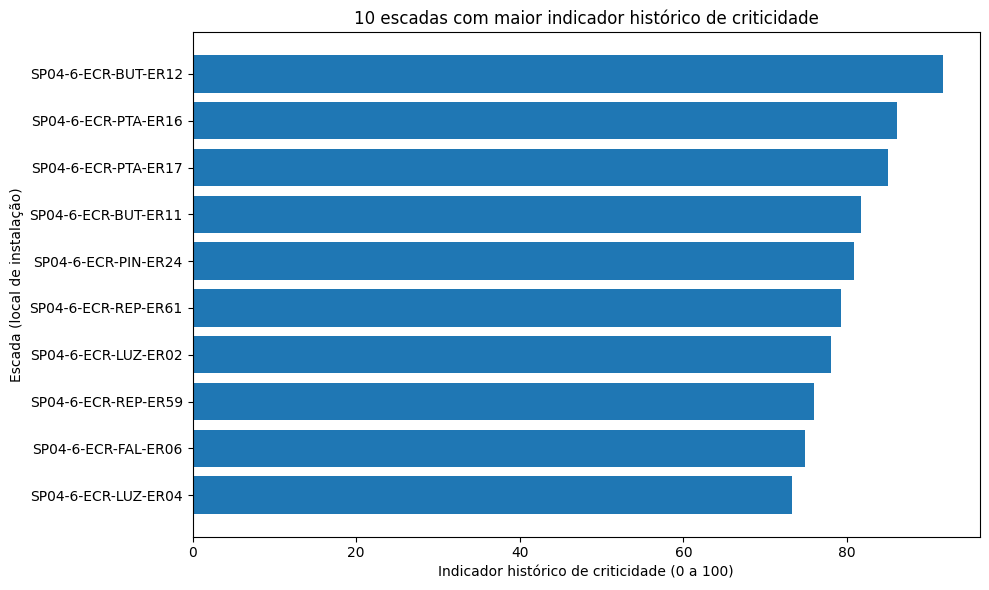

In [13]:
# Corrige os valores ausentes nas marcações de falha e indisponibilidade
base["Tem_falha"] = (
    base["Falha"]
    .astype("string")
    .str.strip()
    .str.upper()
    .eq("X")
    .fillna(False)
)

base["Tem_indisponibilidade"] = (
    base["Indisponível"]
    .astype("string")
    .str.strip()
    .str.upper()
    .eq("X")
    .fillna(False)
)

# Mantém apenas escadas rolantes individuais (padrão SP04-6-ECR-XXX-ERnn).
# Locais de nível estação, como "SP04-6-ECR-PIN", não são escadas e ficam fora do ranking.
PADRAO_ESCADA = r"^SP04-6-ECR-[A-Z]{3}-ER\d+$"

# Teto por registro (30 dias): hipótese para limitar apontamentos de duração implausível
LIMITE_HORAS_POR_REGISTRO = 720

eh_escada = base["Local de Instalação"].str.match(PADRAO_ESCADA, na=False)

# Uma nota pode aparecer em mais de uma linha (uma por causa/ação registrada);
# mantemos uma linha por Nota para não contar a mesma falha duas vezes.
dados_ecr = base[eh_escada].drop_duplicates(subset="Nota").copy()

print(f"Linhas na base: {len(base):,}")
print(f"Linhas de locais que não são escadas (removidas): {(~eh_escada).sum():,}")
print(f"Linhas repetidas da mesma Nota (removidas): {eh_escada.sum() - len(dados_ecr):,}")
print(f"Notas de escadas analisadas: {len(dados_ecr):,}")
print(f"Escadas distintas: {dados_ecr['Local de Instalação'].nunique()}")

# Considera a duração somente nos registros marcados
# como falha ou indisponibilidade, limitada ao teto definido
registro_relevante = (
    dados_ecr["Tem_falha"]
    | dados_ecr["Tem_indisponibilidade"]
)

acima_do_teto = registro_relevante & (dados_ecr["Duracao_avaria_horas"] > LIMITE_HORAS_POR_REGISTRO)
print(
    f"Falhas/indisponibilidades com duração acima de {LIMITE_HORAS_POR_REGISTRO} h "
    f"(limitadas ao teto): {acima_do_teto.sum():,}"
)

dados_ecr["Horas_consideradas"] = (
    dados_ecr["Duracao_avaria_horas"]
    .clip(upper=LIMITE_HORAS_POR_REGISTRO)
    .where(registro_relevante, 0)
)

# Agrupa o histórico por escada
ranking = (
    dados_ecr.groupby("Local de Instalação")
    .agg(
        falhas=("Tem_falha", "sum"),
        indisponibilidades=("Tem_indisponibilidade", "sum"),
        horas_consideradas=("Horas_consideradas", "sum"),
        registros=("Nota", "count")
    )
    .reset_index()
)

# Normaliza cada indicador pelo maior valor observado.
# Isso permite combinar contagens e horas na mesma escala.
def normalizar_por_maximo(serie):
    """Divide a série pelo seu maior valor; devolve zeros se o máximo for 0 ou ausente."""
    maior_valor = serie.max()

    if pd.isna(maior_valor) or maior_valor == 0:
        return serie * 0

    return serie / maior_valor

ranking["falhas_norm"] = normalizar_por_maximo(ranking["falhas"])
ranking["indisponibilidades_norm"] = normalizar_por_maximo(ranking["indisponibilidades"])
ranking["horas_norm"] = normalizar_por_maximo(ranking["horas_consideradas"])

# Calcula o indicador histórico proposto:
# 50% falhas, 30% indisponibilidades e 20% horas consideradas
ranking["criticidade"] = 100 * (
    0.50 * ranking["falhas_norm"]
    + 0.30 * ranking["indisponibilidades_norm"]
    + 0.20 * ranking["horas_norm"]
)

# Ordena da maior para a menor criticidade
ranking = ranking.sort_values(
    "criticidade", ascending=False
).reset_index(drop=True)

ranking.index = ranking.index + 1
ranking.index.name = "Posição"

print("\nRANKING HISTÓRICO DE CRITICIDADE")
print("Indicador proposto para este projeto; não é uma classificação oficial da Motiva.")

display(
    ranking[
        [
            "Local de Instalação",
            "falhas",
            "indisponibilidades",
            "horas_consideradas",
            "criticidade"
        ]
    ].head(15).round(2)
)

# Gráfico das 10 escadas com maior pontuação
top10 = ranking.head(10).sort_values("criticidade")

plt.figure(figsize=(10, 6))
plt.barh(
    top10["Local de Instalação"],
    top10["criticidade"]
)
plt.xlabel("Indicador histórico de criticidade (0 a 100)")
plt.ylabel("Escada (local de instalação)")
plt.title("10 escadas com maior indicador histórico de criticidade")
plt.tight_layout()
plt.show()


**Interpretação.** Depois do tratamento, analisamos 100.854 notas de 201 escadas: removemos 685 linhas de locais que não são escadas e 2.580 linhas repetidas da mesma nota, e limitamos 103 registros de falha ou indisponibilidade com duração acima de 720 h. A escada SP04-6-ECR-BUT-ER12 lidera o ranking (91,68), com 176 falhas e 561 indisponibilidades, seguida por PTA-ER16 (86,13) e PTA-ER17 (84,98). Observamos que a ordem não segue um único indicador: PIN-ER24 tem o maior total de horas entre as cinco primeiras (5.280 h), mas fica em 5º por ter menos falhas (122). Duas escadas da estação República (REP-ER61 e REP-ER59) aparecem entre as oito primeiras.

## **Etapa 3 - Geração de leituras simuladas dos sensores**

Como o conjunto de dados histórico disponibilizado para o projeto não contém as leituras de sensores necessárias para calcular diretamente a degradação física das escadas rolantes, criamos um conjunto de dados sintético para demonstrar o funcionamento do modelo.

Simulamos cinco variáveis: vibração, temperatura, corrente elétrica, nível de óleo e velocidade. Para cada uma das oito escadas selecionadas, geramos 30 leituras, utilizando intervalos de valores definidos para o experimento.

Também utilizamos uma semente fixa na geração dos valores aleatórios, permitindo reproduzir os mesmos dados em execuções sucessivas e comparar os resultados dos algoritmos.

Essas leituras são exclusivamente demonstrativas e não correspondem a medições reais dos equipamentos. Portanto, utilizamos os valores simulados para implementar e avaliar o cálculo de degradação acumulada, sem atribuir a eles a condição física real de qualquer escada.

In [14]:


import numpy as np
import pandas as pd

# Gerador aleatório com semente fixa para reproduzir os resultados
rng = np.random.default_rng(42)

# Seleciona as 8 escadas com maior indicador histórico
escadas_teste = (
    ranking.head(8)["Local de Instalação"].tolist()
)

# Quantidade de leituras simuladas por escada
quantidade_leituras = 30

leituras = []

for escada in escadas_teste:
    for instante in range(quantidade_leituras):

        # Valores sintéticos, apenas para demonstrar o algoritmo
        vibracao = rng.uniform(1.0, 8.0)
        temperatura = rng.uniform(25.0, 85.0)
        corrente = rng.uniform(2.0, 12.0)
        nivel_oleo = rng.uniform(40.0, 100.0)
        velocidade = rng.uniform(0.5, 1.0)

        leituras.append({
            "Escada": escada,
            "Leitura": instante,
            "Vibracao": vibracao,
            "Temperatura": temperatura,
            "Corrente": corrente,
            "Nivel_oleo": nivel_oleo,
            "Velocidade": velocidade
        })

sensores = pd.DataFrame(leituras)

# Calcula um incremento ilustrativo entre 0 e 0,05 por leitura.
# Quanto mais os indicadores se afastam das condições de referência, maior tende a ser o incremento.

sensores["Incremento"] = (
    0.015 * (sensores["Vibracao"] / 8.0)
    + 0.010 * (sensores["Temperatura"] / 85.0)
    + 0.010 * (sensores["Corrente"] / 12.0)
    + 0.010 * (1 - sensores["Nivel_oleo"] / 100.0)
    + 0.005 * (1 - sensores["Velocidade"])
)

sensores = sensores.sort_values(
    ["Escada", "Leitura"]
).reset_index(drop=True)

print("LEITURAS SINTÉTICAS CRIADAS")
print(f"Escadas simuladas: {sensores['Escada'].nunique()}")
print(f"Total de leituras: {len(sensores)}")

display(sensores.head(10))


LEITURAS SINTÉTICAS CRIADAS
Escadas simuladas: 8
Total de leituras: 240


,Escada,Leitura,Vibracao,Temperatura,Corrente,Nivel_oleo,Velocidade,Incremento
0,SP04-6-ECR-BUT-ER11,0,1.296454,78.048743,9.095783,50.387671,0.545861,0.026425
1,SP04-6-ECR-BUT-ER11,1,2.284733,83.801631,6.585606,87.044857,0.818204,0.021835
2,SP04-6-ECR-BUT-ER11,2,5.006892,33.707815,11.460245,58.080558,0.789009,0.028151
3,SP04-6-ECR-BUT-ER11,3,5.898432,63.953989,11.405944,48.906339,0.754176,0.034427
4,SP04-6-ECR-BUT-ER11,4,3.828241,53.450124,3.192175,48.045677,0.639038,0.023127
5,SP04-6-ECR-BUT-ER11,5,3.132932,50.674193,8.109875,78.077747,0.705905,0.022257
6,SP04-6-ECR-BUT-ER11,6,3.861482,38.057712,7.883062,59.022455,0.518030,0.024794
7,SP04-6-ECR-BUT-ER11,7,3.928800,53.447961,4.255929,74.347476,0.782886,0.020852
8,SP04-6-ECR-BUT-ER11,8,5.914015,63.876909,8.524331,58.972849,0.893716,0.030341
9,SP04-6-ECR-BUT-ER11,9,4.844011,50.885092,8.260125,61.639440,0.756370,0.027007


**Interpretação.** Geramos 240 leituras sintéticas, 30 para cada uma das oito escadas com maior criticidade histórica. Pela fórmula, cada incremento fica entre cerca de 0,0065 e 0,0435 por leitura; em 30 leituras, a degradação esperada fica perto de 0,75. Por isso, nesta simulação, o teto de 100% não chega a ser atingido; ele só passaria a agir com séries mais longas ou incrementos maiores.

## **Etapa 4 - Implementação das estratégias de programação dinâmica**

Nesta etapa, implementamos três abordagens para calcular a degradação acumulada das escadas: recursão pura, recursão com memoização e tabulação iterativa.

Definimos cada estado como a degradação acumulada de uma escada após determinada leitura dos sensores. Para calcular o estado atual, somamos a degradação anterior ao incremento correspondente à leitura atual, limitando o resultado a 1, equivalente a 100% no modelo simulado.

Implementamos a recursão pura utilizando chamadas recursivas para calcular cada estado a partir do anterior. Na versão com memoização, armazenamos os resultados já calculados em um dicionário. Na versão iterativa, percorremos as leituras em sequência e registramos a evolução acumulada em uma lista.


In [15]:


def degradacao_recursiva(incrementos, n):
    """
    Recursão pura: recalcula os estados anteriores.
    """
    if n < 0:
        return 0.0

    degradacao_anterior = degradacao_recursiva(
        incrementos, n - 1
    )

    return min(
        1.0,
        degradacao_anterior + incrementos[n]
    )


def degradacao_memoizada(incrementos, n, memo=None):
    """
    Recursão com memoização: armazena resultados já calculados.
    """
    if memo is None:
        memo = {}

    if n < 0:
        return 0.0

    if n in memo:
        return memo[n]

    degradacao_anterior = degradacao_memoizada(
        incrementos, n - 1, memo
    )

    memo[n] = min(
        1.0,
        degradacao_anterior + incrementos[n]
    )

    return memo[n]


def degradacao_tabular(incrementos):
    """
    Tabulação iterativa: calcula cada estado uma única vez.
    """
    tabela = []
    acumulada = 0.0

    for incremento in incrementos:
        acumulada = min(
            1.0,
            acumulada + incremento
        )
        tabela.append(acumulada)

    return tabela


print("As três funções foram definidas.")


As três funções foram definidas.


## **Etapa 5 - Verificação da equivalência das três implementações**

Antes de medir o desempenho, verificamos se as três versões produzem o mesmo resultado. Comparamos recursão pura, memoização e tabulação nas oito escadas simuladas e em todos os 30 prefixos de leituras de cada uma.

Também contamos as chamadas da recursão pura para confirmar, na implementação real, que a quantidade de chamadas cresce de forma linear com o número de leituras.

In [16]:
# Compara as três versões em todas as escadas simuladas e em todos os prefixos de leituras
comparacoes = []

for escada in escadas_teste:
    incrementos = (
        sensores[sensores["Escada"] == escada]
        .sort_values("Leitura")["Incremento"]
        .tolist()
    )
    tabela = degradacao_tabular(incrementos)

    for n in range(len(incrementos)):
        recursivo = degradacao_recursiva(incrementos, n)
        memoizado = degradacao_memoizada(incrementos, n)
        assert np.isclose(recursivo, tabela[n]) and np.isclose(memoizado, tabela[n]), (
            f"Divergência em {escada}, leitura {n}"
        )

    comparacoes.append({
        "Escada": escada,
        "Leituras comparadas": len(incrementos),
        "Recursão pura": degradacao_recursiva(incrementos, len(incrementos) - 1),
        "Memoização": degradacao_memoizada(incrementos, len(incrementos) - 1),
        "Tabulação": tabela[-1],
    })

display(pd.DataFrame(comparacoes).round(6))

# Contagem de chamadas da recursão pura: confirma que ela é linear, não exponencial
contador = {"chamadas": 0}
_recursiva_original = degradacao_recursiva

def degradacao_recursiva(incrementos, n):
    contador["chamadas"] += 1
    return _recursiva_original(incrementos, n)

amostra_contagem = sensores["Incremento"].tolist()

for tamanho in (5, 10, 20, 30):
    contador["chamadas"] = 0
    degradacao_recursiva(amostra_contagem[:tamanho], tamanho - 1)
    print(f"{tamanho} leituras -> {contador['chamadas']} chamadas da recursão pura")

degradacao_recursiva = _recursiva_original   # restaura a função original

print(f"\nTeste aprovado: as três versões coincidem em {len(escadas_teste)} escadas x 30 prefixos.")

,Escada,Leituras comparadas,Recursão pura,Memoização,Tabulação
0,SP04-6-ECR-BUT-ER12,30,0.766808,0.766808,0.766808
1,SP04-6-ECR-PTA-ER16,30,0.754141,0.754141,0.754141
2,SP04-6-ECR-PTA-ER17,30,0.819960,0.819960,0.819960
3,SP04-6-ECR-BUT-ER11,30,0.754228,0.754228,0.754228
4,SP04-6-ECR-PIN-ER24,30,0.738407,0.738407,0.738407
5,SP04-6-ECR-REP-ER61,30,0.735194,0.735194,0.735194
6,SP04-6-ECR-LUZ-ER02,30,0.732932,0.732932,0.732932
7,SP04-6-ECR-REP-ER59,30,0.747601,0.747601,0.747601


5 leituras -> 6 chamadas da recursão pura
10 leituras -> 11 chamadas da recursão pura
20 leituras -> 21 chamadas da recursão pura
30 leituras -> 31 chamadas da recursão pura

Teste aprovado: as três versões coincidem em 8 escadas x 30 prefixos.


**Interpretação.** As três versões produziram o mesmo valor nas oito escadas e em todos os 30 prefixos de cada uma (por exemplo, 0,766808 para BUT-ER12 e 0,819960 para PTA-ER17). A contagem confirma que a recursão pura é linear: 5, 10, 20 e 30 leituras geram 6, 11, 21 e 31 chamadas, ou seja, uma chamada por leitura mais o caso-base. Não há crescimento exponencial porque cada estado depende apenas do anterior.

## **Etapa 6 - Avaliação de desempenho das implementações**

Medimos os tempos das três implementações com séries de 5 a 900 leituras. Para reduzir o ruído do cronômetro, executamos cada função 50 vezes por medição, repetimos a medição 30 vezes e usamos a mediana. Paramos em 900 leituras porque as versões recursivas usam uma chamada por leitura e o Python limita a pilha a cerca de 1.000 chamadas.

Fizemos dois experimentos:

1. **Uma consulta** (degradação após a última leitura). Como cada estado depende só do anterior, a recursão pura já calcula cada estado uma única vez; a memoização acrescenta o custo do dicionário e a tabulação evita o custo das chamadas recursivas.
2. **Várias consultas** (degradação após cada uma das 600 leituras). Aqui a recursão pura refaz os estados anteriores a cada consulta, enquanto a memoização reaproveita o dicionário. É nesse cenário que a memoização evita recomputação.

,Leituras,Recursão pura (µs),Memoização (µs),Tabulação (µs)
0,5,0.77,1.44,0.65
1,10,1.55,2.70,1.15
2,20,2.58,4.93,1.98
3,30,3.85,7.47,2.96
4,100,12.61,25.86,11.17
5,300,60.46,94.16,27.15
6,600,139.20,213.51,52.24
7,900,243.46,366.41,85.44


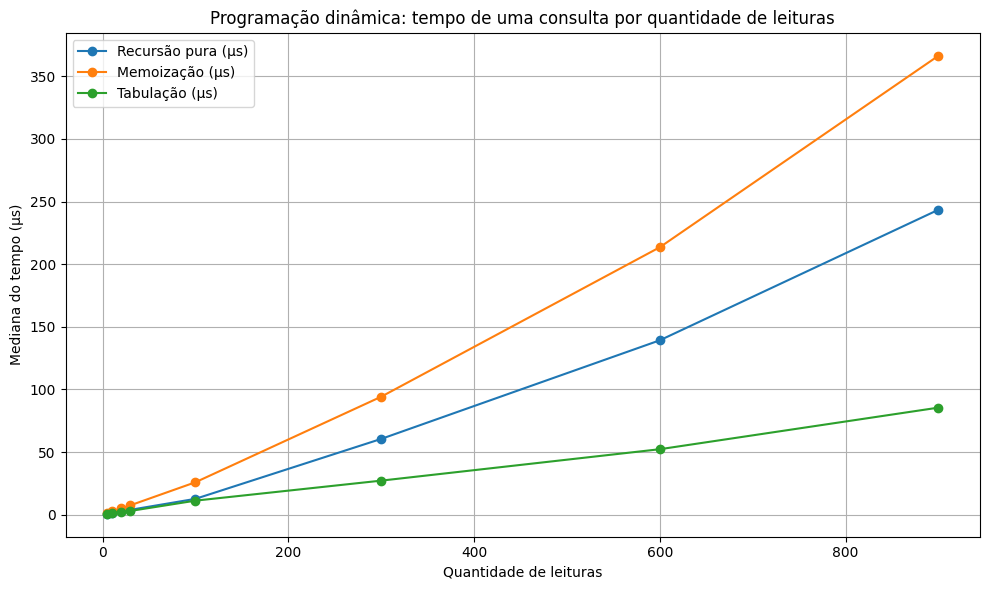

,Consultas,Recursão pura (ms),Memoização compartilhada (ms),Tabulação (ms)
0,600,39.565,0.265,0.052


Com 900 leituras, a versão mais rápida foi: Tabulação.
Em 600 consultas, a memoização compartilhada foi 149x mais rápida que a recursão pura.


In [17]:
import timeit

# Série sintética mais longa, no mesmo intervalo dos incrementos da Etapa 3 (cerca de 0,0065 a 0,0435).
# Paramos em 900 leituras porque o limite de recursão do Python é cerca de 1.000 chamadas.
rng_bench = np.random.default_rng(123)
incrementos_longos = rng_bench.uniform(0.0065, 0.0435, 900).tolist()


def mediana_us(funcao, rodadas=30, chamadas=50):
    """
    Mede `rodadas` vezes; cada medição executa a função `chamadas` vezes e divide
    pelo total (reduz o ruído do cronômetro). Devolve a mediana em microssegundos.
    """
    return statistics.median(
        timeit.timeit(funcao, number=chamadas) / chamadas for _ in range(rodadas)
    ) * 1e6


# 1) Uma consulta: degradação após a última leitura
linhas = []
for tamanho in [5, 10, 20, 30, 100, 300, 600, 900]:
    amostra = incrementos_longos[:tamanho]
    n = tamanho - 1
    referencia = degradacao_tabular(amostra)[-1]
    assert np.isclose(degradacao_recursiva(amostra, n), referencia)
    assert np.isclose(degradacao_memoizada(amostra, n), referencia)

    linhas.append({
        "Leituras": tamanho,
        "Recursão pura (µs)": mediana_us(lambda: degradacao_recursiva(amostra, n)),
        "Memoização (µs)": mediana_us(lambda: degradacao_memoizada(amostra, n)),
        "Tabulação (µs)": mediana_us(lambda: degradacao_tabular(amostra)),
    })

desempenho = pd.DataFrame(linhas)
display(desempenho.round(2))

plt.figure(figsize=(10, 6))
for coluna in ["Recursão pura (µs)", "Memoização (µs)", "Tabulação (µs)"]:
    plt.plot(desempenho["Leituras"], desempenho[coluna], marker="o", label=coluna)
plt.xlabel("Quantidade de leituras")
plt.ylabel("Mediana do tempo (µs)")
plt.title("Programação dinâmica: tempo de uma consulta por quantidade de leituras")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 2) Várias consultas: degradação após cada leitura k = 0..N-1 (todos os prefixos).
# A recursão pura refaz os estados anteriores a cada consulta (~N²/2 chamadas);
# a memoização compartilha o dicionário e calcula cada estado uma única vez (N estados).
N_CONSULTAS = 600

def todas_consultas_puras():
    return [degradacao_recursiva(incrementos_longos, k) for k in range(N_CONSULTAS)]

def todas_consultas_memo():
    memo = {}
    return [degradacao_memoizada(incrementos_longos, k, memo) for k in range(N_CONSULTAS)]

def todas_consultas_tabulacao():
    return degradacao_tabular(incrementos_longos[:N_CONSULTAS])

assert np.allclose(todas_consultas_puras(), todas_consultas_memo())
assert np.allclose(todas_consultas_memo(), todas_consultas_tabulacao())

consultas = pd.DataFrame([{
    "Consultas": N_CONSULTAS,
    "Recursão pura (ms)": mediana_us(todas_consultas_puras, 10, 3) / 1e3,
    "Memoização compartilhada (ms)": mediana_us(todas_consultas_memo, 10, 3) / 1e3,
    "Tabulação (ms)": mediana_us(todas_consultas_tabulacao, 10, 3) / 1e3,
}])
display(consultas.round(3))

# Resumo automático, para a interpretação acompanhar os números desta execução
ultima = desempenho.iloc[-1]
mais_rapida = ultima[["Recursão pura (µs)", "Memoização (µs)", "Tabulação (µs)"]].astype(float).idxmin()
fator = consultas["Recursão pura (ms)"].iloc[0] / consultas["Memoização compartilhada (ms)"].iloc[0]
print(f"Com {int(ultima['Leituras'])} leituras, a versão mais rápida foi: {mais_rapida.replace(' (µs)', '')}.")
print(f"Em {N_CONSULTAS} consultas, a memoização compartilhada foi {fator:.0f}x mais rápida que a recursão pura.")

**Interpretação.** Na consulta única, os três tempos crescem de forma aproximadamente linear com o número de leituras, como previsto pela análise de complexidade O(n). A tabulação foi a mais rápida, por não ter o custo das chamadas recursivas, e a memoização foi a mais lenta, porque acrescenta o custo do dicionário sem evitar nenhum recálculo nesse cenário. No experimento de várias consultas, a situação muda: a recursão pura refaz os estados anteriores a cada consulta (cerca de N²/2 chamadas), enquanto a memoização compartilhada calcula cada estado uma vez, e a diferença passa a ser de dezenas a centenas de vezes (o resumo impresso abaixo da tabela mostra o fator desta execução). Concluímos que, para esta recorrência, a tabulação é a escolha mais adequada, e a memoização só compensa quando o mesmo dicionário atende muitas consultas. Os valores absolutos variam com o ambiente; o que se mantém entre execuções é a forma de crescimento e a ordem entre as versões.

## **Etapa 7 - Degradação acumulada e ranking final de criticidade**

Após verificarmos a equivalência das três implementações, usamos a tabulação para calcular a degradação acumulada de cada uma das oito escadas simuladas.

Em seguida, geramos o ranking final de criticidade. Combinamos a degradação final simulada (escala 0 a 1, convertida para 0 a 100) com o indicador histórico real, com pesos de 50% cada, que são uma hipótese do projeto. Mostramos também a posição que cada escada teria só pela degradação, para deixar visível o efeito de cada fonte.

Mantivemos a distinção entre as duas fontes: a criticidade histórica vem dos registros reais, e a degradação vem das leituras sintéticas. Por isso interpretamos o ranking final como uma demonstração do método, e não como um diagnóstico físico dos equipamentos.

RANKING FINAL DE CRITICIDADE (degradação simulada + histórico real)
Leituras de sensores simuladas; índice acadêmico, não é classificação oficial da Motiva.


,Local de Instalação,Quantidade de leituras,Degradação final simulada,falhas,indisponibilidades,Criticidade histórica (0-100),Criticidade final (0-100),Posição só pela degradação
Posição,,,,,,,,
1,SP04-6-ECR-BUT-ER12,30,0.7668,176,561,91.6834,84.1821,2
2,SP04-6-ECR-PTA-ER17,30,0.8200,168,465,84.9751,83.4855,1
3,SP04-6-ECR-PTA-ER16,30,0.7541,179,472,86.127,80.7706,4
4,SP04-6-ECR-BUT-ER11,30,0.7542,182,316,81.6978,78.5603,3
5,SP04-6-ECR-PIN-ER24,30,0.7384,122,545,80.9034,77.372,6
6,SP04-6-ECR-REP-ER61,30,0.7352,159,373,79.3263,76.4228,7
7,SP04-6-ECR-LUZ-ER02,30,0.7329,150,597,78.0542,75.6737,8
8,SP04-6-ECR-REP-ER59,30,0.7476,143,368,76.0155,75.3878,5


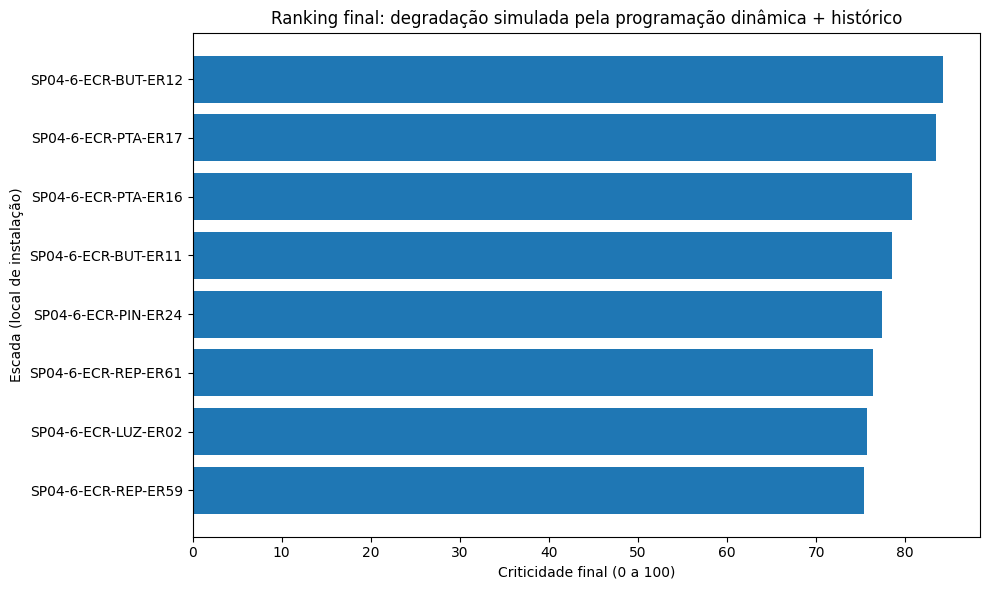

In [18]:
resultados_degradacao = []

for escada in escadas_teste:

    dados_escada = (
        sensores[sensores["Escada"] == escada]
        .sort_values("Leitura")
    )

    incrementos = dados_escada["Incremento"].tolist()

    # Calcula a evolução completa usando tabulação
    evolucao = degradacao_tabular(incrementos)

    if not evolucao:          # escada sem leituras: não entra no ranking de degradação
        continue

    resultados_degradacao.append({
        "Local de Instalação": escada,
        "Quantidade de leituras": len(incrementos),
        "Degradação final simulada": evolucao[-1],
    })

degradacao_final = pd.DataFrame(resultados_degradacao)

# Ranking final de criticidade: combina a degradação simulada (programação dinâmica)
# com o indicador histórico real. Pesos 50/50 são uma hipótese do projeto.
ranking_final = degradacao_final.merge(
    ranking[["Local de Instalação", "falhas", "indisponibilidades", "criticidade"]],
    on="Local de Instalação",
    how="left",
).rename(columns={"criticidade": "Criticidade histórica (0-100)"})

ranking_final["Criticidade final (0-100)"] = (
    50 * ranking_final["Degradação final simulada"]
    + 0.5 * ranking_final["Criticidade histórica (0-100)"]
)

ranking_final = ranking_final.sort_values(
    "Criticidade final (0-100)", ascending=False
).reset_index(drop=True)
ranking_final.index = ranking_final.index + 1
ranking_final.index.name = "Posição"

ranking_final["Posição só pela degradação"] = (
    ranking_final["Degradação final simulada"].rank(ascending=False, method="min").astype(int)
)

print("RANKING FINAL DE CRITICIDADE (degradação simulada + histórico real)")
print("Leituras de sensores simuladas; índice acadêmico, não é classificação oficial da Motiva.")
display(ranking_final.round(4))

# Gráfico da criticidade final
plt.figure(figsize=(10, 6))
plt.barh(
    ranking_final["Local de Instalação"].iloc[::-1],
    ranking_final["Criticidade final (0-100)"].iloc[::-1]
)
plt.xlabel("Criticidade final (0 a 100)")
plt.ylabel("Escada (local de instalação)")
plt.title("Ranking final: degradação simulada pela programação dinâmica + histórico")
plt.tight_layout()
plt.show()

**Interpretação.** No ranking final, BUT-ER12 continua em 1º (84,18), mas PTA-ER17 sobe de 3º para 2º (83,49) por ter a maior degradação simulada (0,8200), à frente de PTA-ER16 (80,77), que tem criticidade histórica maior. REP-ER59 seria a 5ª só pela degradação (0,7476), mas fica em 8º pelo histórico mais baixo. As degradações simuladas variam pouco (0,73 a 0,82), por isso o histórico ainda pesa bastante na ordem final; com leituras reais de sensores, a diferença entre as escadas tenderia a ser maior.

## **Etapa 8 - Rede de estações como grafo: BFS, Dijkstra e A***

Construímos um grafo ponderado para representar os deslocamentos da equipe. Os vértices são a base de manutenção e **todas as 12 estações que têm escadas no dataset**, de modo que cada escada do ranking fica ligada à estação indicada no seu código (por exemplo, `SP04-6-ECR-BUT-ER12` → estação `BUT`). As arestas ligam posições vizinhas de uma grade de quatro colunas e têm peso em minutos de deslocamento, entre 4 e 7. Guardamos o grafo como lista de adjacência.

Implementamos três algoritmos:

- **BFS** (*Breadth-First Search*): encontra o caminho com a menor quantidade de trechos, ignorando os pesos.
- **Dijkstra**: considera os pesos e encontra os menores tempos de deslocamento a partir de uma origem para todos os vértices.
- **A\***: encontra o menor tempo até um destino específico, guiado por uma heurística. Usamos a distância de Manhattan na grade multiplicada pelo menor peso de aresta (4 minutos). Como cada aresta avança uma unidade na grade e custa pelo menos 4 minutos, a heurística nunca superestima o custo restante (**admissível**) e satisfaz $h(u) \le w(u,v) + h(v)$ em toda aresta (**consistente**).

Reconstruímos as rotas a partir dos predecessores registrados nas buscas.

Ressaltamos que a disposição espacial, as ligações e os tempos são hipóteses acadêmicas e não representam a infraestrutura real da Motiva nem os tempos efetivos de viagem.

In [19]:
# IMPORTANTE: os tempos e as conexões são simulados para o projeto.

from collections import deque
import heapq

# Extrai os códigos de estação dos locais de instalação.
# Ex.: SP04-6-ECR-BUT-ER12 -> BUT
dados_ecr["Codigo_estacao"] = (
    dados_ecr["Local de Instalação"]
    .str.split("-")
    .str[-2]
)

# Usa TODAS as estações que têm escadas no dataset (12 na Linha 4), para que
# cada escada fique ligada a uma estação do grafo. Ordem: mais registros primeiro.
contagem_estacoes = (
    dados_ecr["Codigo_estacao"]
    .dropna()
    .value_counts()
)

estacoes = contagem_estacoes.index.tolist()

if len(estacoes) < 8:
    raise ValueError(
        "O enunciado pede pelo menos oito estações; foram encontradas "
        f"{len(estacoes)}."
    )

BASE_MANUTENCAO = "BASE_MANUTENCAO"

# O grafo utiliza a base e todas as estações
nos = [BASE_MANUTENCAO] + [
    f"ESTACAO_{codigo}" for codigo in estacoes
]

# Coordenadas abstratas em uma grade de 4 colunas.
# A base ocupa (0, 0); as estações ocupam as posições seguintes, linha a linha.
COLUNAS_GRADE = 4
coordenadas = {
    no: (indice % COLUNAS_GRADE, indice // COLUNAS_GRADE)
    for indice, no in enumerate(nos)
}

# Lista de adjacência
grafo = {no: [] for no in nos}

# Conecta posições vizinhas na grade (distância de Manhattan = 1).
# Os pesos de 4 a 7 minutos são fictícios e reproduzíveis.
for i in range(len(nos)):
    for j in range(i + 1, len(nos)):
        no_a = nos[i]
        no_b = nos[j]

        xa, ya = coordenadas[no_a]
        xb, yb = coordenadas[no_b]

        distancia_grade = abs(xa - xb) + abs(ya - yb)

        # Só conecta posições vizinhas
        if distancia_grade == 1:
            tempo = 4 + ((i + j) % 4)

            grafo[no_a].append((no_b, tempo))
            grafo[no_b].append((no_a, tempo))

# Menor peso de aresta: base da heurística do A*
PESO_MINIMO = min(peso for vizinhos in grafo.values() for _, peso in vizinhos)

# Confere que toda escada do ranking está ligada a uma estação do grafo
escadas_sem_estacao = [
    escada for escada in ranking["Local de Instalação"]
    if f"ESTACAO_{escada.split('-')[-2]}" not in grafo
]

print("ESTAÇÕES NO GRAFO (todas as que têm escadas no dataset)")
for codigo in estacoes:
    escadas_na_estacao = ranking["Local de Instalação"].str.split("-").str[-2].eq(codigo).sum()
    print(f"- {codigo}: {escadas_na_estacao} escadas")

print(f"\nGrafo criado com {len(nos)} vértices e "
      f"{sum(len(v) for v in grafo.values()) // 2} arestas.")
print(f"Pesos das arestas: {sorted({p for v in grafo.values() for _, p in v})} minutos")
print(f"Escadas sem estação no grafo: {len(escadas_sem_estacao)}")


# 8.1 BFS: encontra o caminho com menos segmentos
def bfs(grafo, origem, destino):
    """Busca em largura: devolve o caminho com MENOS arestas (ignora os pesos), ou None se não houver caminho."""
    fila = deque([(origem, [origem])])
    visitados = {origem}

    while fila:
        atual, caminho = fila.popleft()

        if atual == destino:
            return caminho

        for vizinho, _ in grafo[atual]:
            if vizinho not in visitados:
                visitados.add(vizinho)
                fila.append((vizinho, caminho + [vizinho]))

    return None


# 8.2 Dijkstra: encontra o caminho de menor tempo
def dijkstra(grafo, origem):
    """Dijkstra com fila de prioridade: menores tempos (minutos) da origem a todos os vértices e o predecessor de cada um."""
    distancias = {no: float("inf") for no in grafo}
    anteriores = {no: None for no in grafo}

    distancias[origem] = 0
    fila = [(0, origem)]

    while fila:
        distancia_atual, atual = heapq.heappop(fila)

        if distancia_atual > distancias[atual]:
            continue

        for vizinho, peso in grafo[atual]:
            nova_distancia = distancia_atual + peso

            if nova_distancia < distancias[vizinho]:
                distancias[vizinho] = nova_distancia
                anteriores[vizinho] = atual

                heapq.heappush(
                    fila, (nova_distancia, vizinho)
                )

    return distancias, anteriores


# Reconstrói a rota usando os predecessores
def reconstruir_caminho(anteriores, origem, destino):
    """Refaz a rota seguindo os predecessores do destino até a origem; devolve None se o destino for inalcançável."""
    caminho = []
    atual = destino

    while atual is not None:
        caminho.append(atual)

        if atual == origem:
            break

        atual = anteriores[atual]

    if not caminho or caminho[-1] != origem:
        return None

    return caminho[::-1]


# 8.3 A*: encontra uma rota de menor tempo usando heurística
def astar(grafo, origem, destino, coordenadas):
    """A*: menor tempo da origem até UM destino, guiado pela heurística de Manhattan; devolve (custo, caminho)."""
    def heuristica(no):
        x1, y1 = coordenadas[no]
        x2, y2 = coordenadas[destino]

        # Distância de Manhattan x menor peso de aresta (PESO_MINIMO).
        # Cada aresta liga posições vizinhas (1 passo na grade) e custa
        # pelo menos PESO_MINIMO minutos; logo a heurística não superestima
        # o custo restante (admissível) e h(u) <= peso(u, v) + h(v) (consistente).
        return PESO_MINIMO * (abs(x1 - x2) + abs(y1 - y2))

    custos = {no: float("inf") for no in grafo}
    anteriores = {no: None for no in grafo}

    custos[origem] = 0
    fila = [(heuristica(origem), 0, origem)]

    while fila:
        _, custo_atual, atual = heapq.heappop(fila)

        if custo_atual > custos[atual]:
            continue

        if atual == destino:
            break

        for vizinho, peso in grafo[atual]:
            novo_custo = custo_atual + peso

            if novo_custo < custos[vizinho]:
                custos[vizinho] = novo_custo
                anteriores[vizinho] = atual

                prioridade = novo_custo + heuristica(vizinho)

                heapq.heappush(
                    fila, (prioridade, novo_custo, vizinho)
                )

    caminho = reconstruir_caminho(
        anteriores, origem, destino
    )

    return custos[destino], caminho


# 8.4 Calcula e exibe as rotas para todas as estações
def custo_do_caminho(grafo, caminho):
    """Soma os pesos (minutos) das arestas de um caminho."""
    return sum(dict(grafo[a])[b] for a, b in zip(caminho, caminho[1:]))


distancias, anteriores = dijkstra(grafo, BASE_MANUTENCAO)

resultados_rotas = []

for codigo in estacoes:
    destino = f"ESTACAO_{codigo}"

    caminho_bfs = bfs(grafo, BASE_MANUTENCAO, destino)
    caminho_dijkstra = reconstruir_caminho(anteriores, BASE_MANUTENCAO, destino)
    custo_astar, caminho_astar = astar(grafo, BASE_MANUTENCAO, destino, coordenadas)

    if None in (caminho_bfs, caminho_dijkstra, caminho_astar):
        resultados_rotas.append({"Estação": codigo, "Rota_BFS": "sem caminho"})
        continue

    resultados_rotas.append({
        "Estação": codigo,
        "Segmentos_BFS": len(caminho_bfs) - 1,
        "Tempo_do_caminho_BFS_min": custo_do_caminho(grafo, caminho_bfs),
        "Segmentos_Dijkstra": len(caminho_dijkstra) - 1,
        "Tempo_Dijkstra_min": distancias[destino],
        "Rota_BFS": " -> ".join(caminho_bfs),
        "Rota_Dijkstra": " -> ".join(caminho_dijkstra),
    })

rotas = pd.DataFrame(resultados_rotas)
pd.set_option("display.max_colwidth", None)
display(rotas)

ESTAÇÕES NO GRAFO (todas as que têm escadas no dataset)
- PIN: 32 escadas
- LUZ: 20 escadas
- PTA: 18 escadas
- BUT: 14 escadas
- HIG: 26 escadas
- FAL: 10 escadas
- FRE: 20 escadas
- MBI: 15 escadas
- VSO: 20 escadas
- FRA: 10 escadas
- REP: 7 escadas
- TVS: 9 escadas

Grafo criado com 13 vértices e 18 arestas.
Pesos das arestas: [4, 5, 6, 7] minutos
Escadas sem estação no grafo: 0


,Estação,Segmentos_BFS,Tempo_do_caminho_BFS_min,Segmentos_Dijkstra,Tempo_Dijkstra_min,Rota_BFS,Rota_Dijkstra
0,PIN,1,5,1,5,BASE_MANUTENCAO -> ESTACAO_PIN,BASE_MANUTENCAO -> ESTACAO_PIN
1,LUZ,2,12,2,12,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ
2,PTA,3,17,3,17,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_PTA,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_PTA
3,BUT,1,4,1,4,BASE_MANUTENCAO -> ESTACAO_BUT,BASE_MANUTENCAO -> ESTACAO_BUT
4,HIG,2,11,2,9,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_HIG,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_HIG
5,FAL,3,16,3,16,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_FAL,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_HIG -> ESTACAO_FAL
6,FRE,4,23,4,21,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_PTA -> ESTACAO_FRE,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_HIG -> ESTACAO_FAL -> ESTACAO_FRE
7,MBI,2,8,2,8,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI
8,VSO,3,17,3,13,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_HIG -> ESTACAO_VSO,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI -> ESTACAO_VSO
9,FRA,4,20,4,20,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_FAL -> ESTACAO_FRA,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI -> ESTACAO_VSO -> ESTACAO_FRA


**Interpretação.** O grafo tem 13 vértices (a base e as 12 estações) e 18 arestas, com pesos de 4 a 7 minutos, e nenhuma das 201 escadas fica sem estação. BFS e Dijkstra coincidem na maioria dos destinos, mas não em todos: para HIG, o BFS escolhe a rota BASE → PIN → HIG, com 2 trechos e 11 minutos, enquanto Dijkstra encontra uma rota de 2 trechos e 9 minutos; para FRE, VSO e REP, o caminho do BFS custa 23, 17 e 29 minutos, contra 21, 13 e 25 minutos de Dijkstra. Isso confirma que o BFS minimiza a quantidade de trechos, e não o tempo.

## **Exportação dos dados utilizados**

 Gravamos as leituras simuladas, os dois rankings e a rede de estações (vértices, coordenadas, arestas com minutos e escadas de cada estação) para publicar no repositório GitHub junto com o notebook. Os arquivos ficam na pasta `dados/`.


In [20]:
import json
import os

PASTA_DADOS = "dados"
os.makedirs(PASTA_DADOS, exist_ok=True)

# Grava os dados usados pelos algoritmos (o enunciado pede dataset e rede em CSV, Excel ou JSON)
sensores.to_csv(os.path.join(PASTA_DADOS, "sensores_simulados.csv"), index=False)          # leituras SIMULADAS
ranking.to_csv(os.path.join(PASTA_DADOS, "ranking_criticidade_historica.csv"))             # ranking com dados reais
ranking_final.to_csv(os.path.join(PASTA_DADOS, "ranking_criticidade_final.csv"))           # degradação simulada + histórico

rede = {
    "aviso": "Rede e tempos simulados para o projeto; não representam a infraestrutura real da Motiva.",
    "base": BASE_MANUTENCAO,
    "coordenadas": {no: list(c) for no, c in coordenadas.items()},
    "arestas": [
        {"origem": a, "destino": b, "minutos": w}
        for a in grafo for b, w in grafo[a] if a < b
    ],
    "escadas_por_estacao": {
        f"ESTACAO_{codigo}": sorted(
            ranking.loc[ranking["Local de Instalação"].str.split("-").str[-2] == codigo,
                        "Local de Instalação"].tolist()
        )
        for codigo in estacoes
    },
}

with open(os.path.join(PASTA_DADOS, "rede_estacoes.json"), "w", encoding="utf-8") as arquivo:
    json.dump(rede, arquivo, ensure_ascii=False, indent=2)

print(f"Arquivos gerados na pasta {PASTA_DADOS}/:")
for nome in ["sensores_simulados.csv", "ranking_criticidade_historica.csv",
             "ranking_criticidade_final.csv", "rede_estacoes.json"]:
    print(f"- {nome}")
print(f"Arestas gravadas: {len(rede['arestas'])}")

Arquivos gerados na pasta dados/:
- sensores_simulados.csv
- ranking_criticidade_historica.csv
- ranking_criticidade_final.csv
- rede_estacoes.json
Arestas gravadas: 18


## **Etapa 9 - Validação dos caminhos e comparação dos resultados**

Nesta etapa, comparamos os custos calculados pelo A* com os resultados obtidos pelo algoritmo de Dijkstra para cada estação. Utilizamos Dijkstra como referência para verificar se o A* encontra os mesmos custos mínimos no grafo avaliado.

Criamos uma tabela para registrar o tempo calculado por cada algoritmo e indicar se os resultados são iguais. Essa comparação nos permite verificar a consistência dos custos mínimos obtidos.

Também distinguimos a qualidade das soluções do desempenho computacional. Embora dois algoritmos possam encontrar caminhos com o mesmo custo mínimo, eles podem explorar quantidades diferentes de vértices e apresentar tempos de execução distintos.

Além das rotas a partir da base, comparamos os custos de A* e Dijkstra em todos os pares origem-destino do grafo.

In [21]:
comparacao_astar = []

for codigo in estacoes:
    destino = f"ESTACAO_{codigo}"

    # Resultado de Dijkstra a partir da base
    distancia_dijkstra = distancias[destino]

    # Resultado de A* a partir da base
    distancia_astar, caminho_astar = astar(
        grafo,
        BASE_MANUTENCAO,
        destino,
        coordenadas
    )

    comparacao_astar.append({
        "Estação": codigo,
        "Dijkstra (min)": distancia_dijkstra,
        "A* (min)": distancia_astar,
        "Resultados iguais": distancia_dijkstra == distancia_astar,
        "Rota A*": " -> ".join(caminho_astar)
    })

comparacao_astar = pd.DataFrame(comparacao_astar)

display(comparacao_astar)

print(
    "\nTodas as estações têm o mesmo custo mínimo a partir da base?",
    comparacao_astar["Resultados iguais"].all()
)

# Validação mais ampla: todos os pares origem-destino do grafo
pares_iguais = 0
for origem in grafo:
    distancias_origem, _ = dijkstra(grafo, origem)
    for destino in grafo:
        pares_iguais += astar(grafo, origem, destino, coordenadas)[0] == distancias_origem[destino]

print(f"A* = Dijkstra em {pares_iguais} de {len(grafo) ** 2} pares origem-destino.")

,Estação,Dijkstra (min),A* (min),Resultados iguais,Rota A*
0,PIN,5,5,True,BASE_MANUTENCAO -> ESTACAO_PIN
1,LUZ,12,12,True,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ
2,PTA,17,17,True,BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_PTA
3,BUT,4,4,True,BASE_MANUTENCAO -> ESTACAO_BUT
4,HIG,9,9,True,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_HIG
5,FAL,16,16,True,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_HIG -> ESTACAO_FAL
6,FRE,21,21,True,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_HIG -> ESTACAO_FAL -> ESTACAO_FRE
7,MBI,8,8,True,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI
8,VSO,13,13,True,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI -> ESTACAO_VSO
9,FRA,20,20,True,BASE_MANUTENCAO -> ESTACAO_BUT -> ESTACAO_MBI -> ESTACAO_VSO -> ESTACAO_FRA



Todas as estações têm o mesmo custo mínimo a partir da base? True
A* = Dijkstra em 169 de 169 pares origem-destino.


**Interpretação.** O A* encontrou o mesmo custo mínimo de Dijkstra para as 12 estações a partir da base e, na validação ampliada, para os 169 pares origem-destino do grafo. As rotas do A* também coincidem com as de Dijkstra em todos os destinos a partir da base. O resultado é coerente com a heurística ser admissível e consistente, condição que garante que o A* devolva o caminho ótimo.

## **Etapa 10 - Comparação do desempenho de Dijkstra e A***

Para comparar os dois algoritmos com entradas equivalentes, usamos uma versão de Dijkstra que para ao fechar o destino, da mesma forma que o A*. Assim, os dois resolvem exatamente o mesmo problema: uma origem e um destino.

Medimos cada algoritmo com 2.000 execuções por medição e 30 medições, usando a mediana. Também contamos quantos nós cada um expande, uma medida que não depende do ambiente de execução e mostra o efeito da heurística.

In [22]:
# Benchmark Dijkstra x A*: entradas equivalentes (mesma origem e mesmo destino), muitas repetições e nós expandidos

def dijkstra_ate_destino(grafo, origem, destino):
    """Mesma lógica do dijkstra do notebook, mas para ao fechar o destino (comparação justa com o A*)."""
    distancias = {no: float("inf") for no in grafo}
    distancias[origem] = 0
    fila, expandidos = [(0, origem)], 0
    while fila:
        d, atual = heapq.heappop(fila)
        if d > distancias[atual]:
            continue
        expandidos += 1
        if atual == destino:
            break
        for viz, peso in grafo[atual]:
            nd = d + peso
            if nd < distancias[viz]:
                distancias[viz] = nd
                heapq.heappush(fila, (nd, viz))
    return distancias[destino], expandidos

def astar_expandidos(grafo, origem, destino, coordenadas):
    """Mesma lógica do astar do notebook, contando quantos nós foram expandidos."""
    h = lambda n: PESO_MINIMO * (abs(coordenadas[n][0] - coordenadas[destino][0]) + abs(coordenadas[n][1] - coordenadas[destino][1]))
    custos = {no: float("inf") for no in grafo}
    custos[origem] = 0
    fila, expandidos = [(h(origem), 0, origem)], 0
    while fila:
        _, c, atual = heapq.heappop(fila)
        if c > custos[atual]:
            continue
        expandidos += 1
        if atual == destino:
            break
        for viz, peso in grafo[atual]:
            nc = c + peso
            if nc < custos[viz]:
                custos[viz] = nc
                heapq.heappush(fila, (nc + h(viz), nc, viz))
    return custos[destino], expandidos

def mediana_us(funcao, rodadas=30, chamadas=2000):
    """Mediana de `rodadas` medições; cada medição executa `chamadas` vezes (reduz ruído do cronômetro)."""
    return statistics.median(
        timeit.timeit(funcao, number=chamadas) / chamadas for _ in range(rodadas)
    ) * 1e6

linhas = []
for codigo in estacoes:
    destino = f"ESTACAO_{codigo}"
    custo_d, exp_d = dijkstra_ate_destino(grafo, BASE_MANUTENCAO, destino)
    custo_a, exp_a = astar_expandidos(grafo, BASE_MANUTENCAO, destino, coordenadas)
    assert custo_d == custo_a, "custos diferentes"
    linhas.append({
        "Estação": codigo,
        "Custo (min)": custo_d,
        "Nós expandidos - Dijkstra": exp_d,
        "Nós expandidos - A*": exp_a,
        "Dijkstra (µs)": mediana_us(lambda: dijkstra_ate_destino(grafo, BASE_MANUTENCAO, destino)),
        "A* (µs)": mediana_us(lambda: astar_expandidos(grafo, BASE_MANUTENCAO, destino, coordenadas)),
    })
benchmark = pd.DataFrame(linhas)
display(benchmark.round(2))

mediana_d = benchmark["Dijkstra (µs)"].median()
mediana_a = benchmark["A* (µs)"].median()
a_mais_rapido = int((benchmark["A* (µs)"] < benchmark["Dijkstra (µs)"]).sum())
print(f"\nMediana entre destinos - Dijkstra: {mediana_d:.2f} µs | A*: {mediana_a:.2f} µs")
print(f"Diferença relativa (A* vs Dijkstra): {100 * (mediana_d - mediana_a) / mediana_d:+.1f}%")
print(f"A* foi mais rápido em {a_mais_rapido} de {len(benchmark)} destinos.")
print("Nós expandidos (soma) - Dijkstra:", benchmark["Nós expandidos - Dijkstra"].sum(),
      "| A*:", benchmark["Nós expandidos - A*"].sum())

,Estação,Custo (min),Nós expandidos - Dijkstra,Nós expandidos - A*,Dijkstra (µs),A* (µs)
0,PIN,5,3,2,4.45,4.74
1,LUZ,12,6,3,7.38,7.07
2,PTA,17,10,4,9.48,7.84
3,BUT,4,2,2,3.42,4.79
4,HIG,9,5,4,6.57,7.37
5,FAL,16,9,6,15.79,20.93
6,FRE,21,12,8,20.20,13.01
7,MBI,8,4,3,5.02,6.88
8,VSO,13,8,6,8.74,10.23
9,FRA,20,11,9,10.30,14.29



Mediana entre destinos - Dijkstra: 8.14 µs | A*: 8.05 µs
Diferença relativa (A* vs Dijkstra): +1.1%
A* foi mais rápido em 3 de 12 destinos.
Nós expandidos (soma) - Dijkstra: 90 | A*: 63


**Interpretação.** O efeito da heurística aparece com clareza nos nós expandidos: somando os 12 destinos, o A* expandiu 63 nós, contra 90 de Dijkstra, cerca de 30% a menos. O ganho é maior nos destinos em que a heurística orienta bem a busca, como PTA (4 contra 10 nós). Nos tempos, porém, a vantagem não se repete: a diferença é de poucos microssegundos e, dependendo da execução, pode favorecer qualquer um dos dois, pois o custo de calcular a heurística compensa a economia de nós num grafo de 13 vértices (ver o resumo impresso abaixo da tabela). Concluímos que, neste grafo, o A* reduz o trabalho de busca, mas não podemos afirmar que seja mais rápido em geral; essa vantagem tende a aparecer em grafos maiores.

## **Etapa 11 - Plano de manutenção do turno: `planejar_turno(base, horas)`**

Implementamos a função `planejar_turno(base, horas)`, que integra o ranking de criticidade e as rotas calculadas. A função percorre as escadas da mais para a menos crítica e, para cada uma, calcula com Dijkstra o menor caminho **a partir da posição atual da equipe**. A escada entra no plano se o deslocamento mais os 30 minutos de manutenção (hipótese do projeto) ainda couberem no tempo restante do turno. Ao final, a função mostra quais escadas atender, em que ordem e por qual caminho.

Escadas da mesma estação têm deslocamento zero entre si, pois a equipe já está no local. O parâmetro `retornar_base` permite contabilizar também a volta à base ao fim do turno.

A estratégia é **gulosa**: ela sempre gera um plano viável, que nunca ultrapassa a duração do turno, mas não garante o plano globalmente ótimo. Uma escolha diferente de ordem poderia, em alguns casos, encaixar mais manutenções no mesmo tempo.

In [23]:
# Planejamento do turno: usa o ranking de criticidade e as rotas de Dijkstra a partir da posição atual da equipe
DURACAO_MANUTENCAO_MIN = 30  # Hipótese demonstrativa do projeto

ranking_planejamento = ranking.copy()
ranking_planejamento["Codigo_estacao"] = (
    ranking_planejamento["Local de Instalação"].astype("string").str.split("-").str[-2]
)

def planejar_turno(base, horas, retornar_base=False, verbose=True):
    """
    Heurística GULOSA: percorre as escadas da mais para a menos crítica e atende cada uma
    se (deslocamento a partir da posição atual + manutenção [+ retorno à base]) ainda couber
    no turno. Gera um plano VIÁVEL; não garante o plano globalmente ótimo.
    """
    if base not in grafo:
        raise ValueError(f"A base '{base}' não existe no grafo.")
    if horas <= 0:
        raise ValueError("A duração do turno deve ser maior que zero.")

    tempo_disponivel = horas * 60
    tempo_utilizado = 0
    local_atual = base
    plano, ignoradas = [], []

    for _, escada in ranking_planejamento.sort_values("criticidade", ascending=False).iterrows():
        nome_escada = escada["Local de Instalação"]
        codigo = escada["Codigo_estacao"]
        destino = f"ESTACAO_{codigo}"

        if destino not in grafo:                      # estação fora da rede simulada
            ignoradas.append((nome_escada, "estação fora do grafo"))
            continue

        distancias, anteriores = dijkstra(grafo, local_atual)
        deslocamento = distancias[destino]
        if deslocamento == float("inf"):              # sem caminho válido
            ignoradas.append((nome_escada, "sem caminho"))
            continue

        tempo_total = deslocamento + DURACAO_MANUTENCAO_MIN
        retorno = dijkstra(grafo, destino)[0][base] if retornar_base else 0
        if tempo_utilizado + tempo_total + retorno > tempo_disponivel:
            continue

        caminho = reconstruir_caminho(anteriores, local_atual, destino)
        plano.append({
            "Ordem": len(plano) + 1,
            "Escada": nome_escada,
            "Estação": codigo,
            "Criticidade histórica": round(escada["criticidade"], 2),
            "Deslocamento (min)": deslocamento,
            "Manutenção estimada (min)": DURACAO_MANUTENCAO_MIN,
            "Tempo total (min)": tempo_total,
            "Rota percorrida": " -> ".join(caminho),
        })
        tempo_utilizado += tempo_total
        local_atual = destino

    if retornar_base and plano:
        tempo_utilizado += dijkstra(grafo, local_atual)[0][base]

    plano_df = pd.DataFrame(plano)
    assert tempo_utilizado <= tempo_disponivel          # o plano nunca estoura o turno
    if verbose:
        print(f"Base: {base} | Turno: {horas} h | Retorno à base contabilizado: {retornar_base}")
        print(f"Tempo utilizado: {tempo_utilizado} min | restante: {tempo_disponivel - tempo_utilizado} min")
        print(f"Manutenções planejadas: {len(plano_df)}")
    return plano_df

plano_turno = planejar_turno(BASE_MANUTENCAO, 4)
display(plano_turno)

# Mesmo turno contabilizando a volta da equipe à base no fim do turno
print()
plano_turno_com_retorno = planejar_turno(BASE_MANUTENCAO, 4, retornar_base=True)
display(plano_turno_com_retorno)

Base: BASE_MANUTENCAO | Turno: 4 h | Retorno à base contabilizado: False
Tempo utilizado: 235 min | restante: 5 min
Manutenções planejadas: 6


,Ordem,Escada,Estação,Criticidade histórica,Deslocamento (min),Manutenção estimada (min),Tempo total (min),Rota percorrida
0,1,SP04-6-ECR-BUT-ER12,BUT,91.68,4,30,34,BASE_MANUTENCAO -> ESTACAO_BUT
1,2,SP04-6-ECR-PTA-ER16,PTA,86.13,21,30,51,ESTACAO_BUT -> BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_PTA
2,3,SP04-6-ECR-PTA-ER17,PTA,84.98,0,30,30,ESTACAO_PTA
3,4,SP04-6-ECR-BUT-ER11,BUT,81.70,21,30,51,ESTACAO_PTA -> ESTACAO_LUZ -> ESTACAO_FAL -> ESTACAO_HIG -> ESTACAO_BUT
4,5,SP04-6-ECR-PIN-ER24,PIN,80.90,9,30,39,ESTACAO_BUT -> BASE_MANUTENCAO -> ESTACAO_PIN
5,6,SP04-6-ECR-PIN-ER22,PIN,58.08,0,30,30,ESTACAO_PIN



Base: BASE_MANUTENCAO | Turno: 4 h | Retorno à base contabilizado: True
Tempo utilizado: 240 min | restante: 0 min
Manutenções planejadas: 6


,Ordem,Escada,Estação,Criticidade histórica,Deslocamento (min),Manutenção estimada (min),Tempo total (min),Rota percorrida
0,1,SP04-6-ECR-BUT-ER12,BUT,91.68,4,30,34,BASE_MANUTENCAO -> ESTACAO_BUT
1,2,SP04-6-ECR-PTA-ER16,PTA,86.13,21,30,51,ESTACAO_BUT -> BASE_MANUTENCAO -> ESTACAO_PIN -> ESTACAO_LUZ -> ESTACAO_PTA
2,3,SP04-6-ECR-PTA-ER17,PTA,84.98,0,30,30,ESTACAO_PTA
3,4,SP04-6-ECR-BUT-ER11,BUT,81.70,21,30,51,ESTACAO_PTA -> ESTACAO_LUZ -> ESTACAO_FAL -> ESTACAO_HIG -> ESTACAO_BUT
4,5,SP04-6-ECR-PIN-ER24,PIN,80.90,9,30,39,ESTACAO_BUT -> BASE_MANUTENCAO -> ESTACAO_PIN
5,6,SP04-6-ECR-PIN-ER22,PIN,58.08,0,30,30,ESTACAO_PIN


**Interpretação.** Num turno de 4 horas a partir da base, o plano atende 6 escadas e usa 235 dos 240 minutos, restando 5. As cinco primeiras são as mais críticas do ranking (BUT-ER12, PTA-ER16, PTA-ER17, BUT-ER11 e PIN-ER24), e a sexta, PIN-ER22 (58,08), entra porque está na mesma estação de PIN-ER24 e não exige deslocamento. Observamos o efeito da estratégia gulosa: a equipe vai de BUT a PTA e depois volta a BUT (21 minutos em cada trecho), porque segue a ordem de criticidade sem agrupar escadas da mesma estação. Contabilizando o retorno à base, o plano é o mesmo e usa os 240 minutos inteiros.

## **Conclusão e limitações**

Implementamos a degradação acumulada com recursão pura, memoização e tabulação e verificamos que as três produzem os mesmos resultados. Mostramos, com a contagem de chamadas, que a recursão pura é linear nesta recorrência, e que a memoização só traz ganho quando várias consultas compartilham o mesmo dicionário. Combinamos a degradação simulada com o histórico real para gerar o ranking final de criticidade. Modelamos a rede com a base e as 12 estações que têm escadas, de modo que todas as escadas ficaram ligadas a uma estação, e confirmamos que BFS minimiza trechos, que Dijkstra minimiza tempo e que o A*, com heurística admissível e consistente, encontra os mesmos custos ótimos expandindo menos nós. Por fim, a função `planejar_turno` integrou o ranking e as rotas e gerou um plano viável para o turno.

**Limitações**

- As leituras de sensores, a rede de estações, os tempos de deslocamento e a duração de 30 minutos por manutenção são simulados ou hipóteses; os resultados de degradação e de rotas demonstram os algoritmos e não descrevem a condição real das escadas.
- A fórmula de incremento de degradação e os pesos dos índices (50/30/20 no histórico e 50/50 no ranking final) foram definidos por nós, sem validação industrial.
- O ranking histórico depende da qualidade dos apontamentos: removemos locais que não são escadas e notas repetidas e limitamos durações a 720 h, mas notas automáticas e registros incompletos ainda podem influenciar o resultado.
- O planejamento do turno é guloso e não garante a solução ótima.
- Os tempos medidos variam com o ambiente de execução; por isso apoiamos as conclusões também na contagem de chamadas e de nós expandidos.